# Camelyon17 — SmallCNN with Data Augmentation

ELE680 — Group 7: Tumor Detection across Hospitals

## Objective
Train a SmallCNN using data augmentation and compare its performance
against the SmallCNN baseline without augmentation.

We use the official Camelyon17-WILDS hospital splits to investigate
how well the model generalizes to unseen hospitals.

In [5]:
import torch
import torchvision
import numpy as np
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.5.1+cu118
CUDA available: True


In [6]:
from wilds import get_dataset

DATA_ROOT = "/mnt/beegfs/scratch/camelyon17/data"

dataset = get_dataset(
    dataset="camelyon17",
    root_dir=DATA_ROOT,
    download=False
)

print("Dataset loaded successfully!")
print("Total image patches:", len(dataset))

Dataset loaded successfully!
Total image patches: 455954


In [8]:
train_data = dataset.get_subset("train")
id_val_data = dataset.get_subset("id_val")
ood_val_data = dataset.get_subset("val")
test_data = dataset.get_subset("test")

print("Training images:", len(train_data))
print("ID validation images:", len(id_val_data))
print("OOD validation images:", len(ood_val_data))
print("Test images:", len(test_data))

Training images: 302436
ID validation images: 33560
OOD validation images: 34904
Test images: 85054


In [9]:
from torchvision import transforms

IMAGE_SIZE = 96

# Training augmentation
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    # 1. Horizontal flip
    transforms.RandomHorizontalFlip(p=0.5),

    # 2. Vertical flip
    transforms.RandomVerticalFlip(p=0.5),

    # 3. Rotation by multiples of 90 degrees
    transforms.RandomChoice([
        transforms.RandomRotation((0, 0)),
        transforms.RandomRotation((90, 90)),
        transforms.RandomRotation((180, 180)),
        transforms.RandomRotation((270, 270)),
    ]),

    # 4. Mild color jitter
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),

    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# Validation and test: no random augmentation
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

print("All four augmentation types are ready!")

All four augmentation types are ready!


In [10]:
train_data = dataset.get_subset(
    "train",
    transform=train_transform
)

id_val_data = dataset.get_subset(
    "id_val",
    transform=eval_transform
)

ood_val_data = dataset.get_subset(
    "val",
    transform=eval_transform
)

test_data = dataset.get_subset(
    "test",
    transform=eval_transform
)


print("Training images:", len(train_data))

Training images: 302436


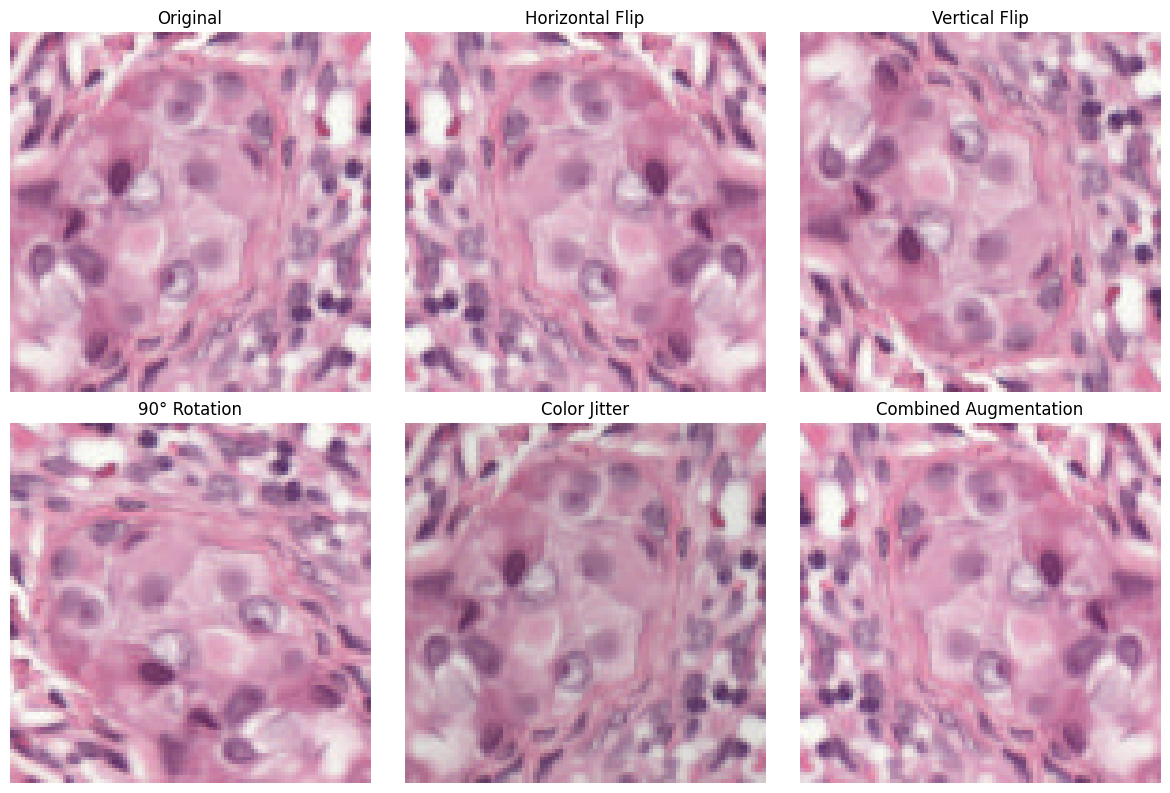

In [15]:
import matplotlib.pyplot as plt
from torchvision import transforms

# Use the same original training image for every example
original_image, label, metadata = dataset.get_subset("train")[0]

resize = transforms.Resize((96, 96))

# Apply each augmentation separately
horizontal_flip = transforms.RandomHorizontalFlip(p=1.0)
vertical_flip = transforms.RandomVerticalFlip(p=1.0)
rotation_90 = transforms.RandomRotation((90, 90))

color_jitter = transforms.ColorJitter(
    brightness=0.1,
    contrast=0.1,
    saturation=0.1
)

images = [
    resize(original_image),
    horizontal_flip(resize(original_image)),
    vertical_flip(resize(original_image)),
    rotation_90(resize(original_image)),
    color_jitter(resize(original_image))
]

# Combined augmentation is normalized, so undo normalization for display
combined_tensor = train_transform(original_image)
combined_image = transforms.ToPILImage()(
    (combined_tensor * 0.5 + 0.5).clamp(0, 1)
)

images.append(combined_image)

titles = [
    "Original",
    "Horizontal Flip",
    "Vertical Flip",
    "90° Rotation",
    "Color Jitter",
    "Combined Augmentation"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [2]:
import torch.nn as nn

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 192, kernel_size=3, padding=1),
            nn.BatchNorm2d(192),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Linear(192, 2)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

model = SmallCNN()

print(model)

SmallCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)


In [18]:
# Get one augmented training image
image, label, metadata = train_data[0]

# Add a batch dimension: [3, 96, 96] -> [1, 3, 96, 96]
image_batch = image.unsqueeze(0)

# Test the model without training it
model.eval()

with torch.no_grad():
    output = model(image_batch)

print("Input shape:", image_batch.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([1, 3, 96, 96])
Output shape: torch.Size([1, 2])


In [19]:
# Training settings
BATCH_SIZE = 8
EPOCHS = 16
LEARNING_RATE = 0.001
NUM_WORKERS = 4

# Use a GPU when available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Data loader workers:", NUM_WORKERS)
print("Device:", device)

Batch size: 8
Epochs: 16
Learning rate: 0.001
Data loader workers: 4
Device: cuda


In [20]:
import torch.optim as optim

# Move SmallCNN to the GPU
model = model.to(device)

# Loss function for normal vs. tumor classification
criterion = nn.CrossEntropyLoss()

# Optimizer updates the model weights during training
optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Model device:", next(model.parameters()).device)
print("Loss function:", criterion)
print("Optimizer: AdamW")

Model device: cuda:0
Loss function: CrossEntropyLoss()
Optimizer: AdamW


In [21]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Training images:", len(train_data))

Training batches: 37805
Training images: 302436


In [22]:
id_val_loader = DataLoader(
    id_val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

ood_val_loader = DataLoader(
    ood_val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("ID validation batches:", len(id_val_loader))
print("OOD validation batches:", len(ood_val_loader))

ID validation batches: 4195
OOD validation batches: 4363


In [11]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score

def calculate_metrics(y_true, y_pred, y_prob):
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "auc": roc_auc_score(y_true, y_prob)
    }
    return metrics


In [12]:
def evaluate_model(model, data_loader, device):
    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():
        for images, labels, metadata in data_loader:
            images = images.to(device)

            outputs = model(images)

            probabilities = torch.softmax(outputs, dim=1)[:, 1]
            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.cpu().tolist())
            all_predictions.extend(predictions.cpu().tolist())
            all_probabilities.extend(probabilities.cpu().tolist())

    return calculate_metrics(
        all_labels,
        all_predictions,
        all_probabilities
    )


In [13]:
from pathlib import Path

CHECKPOINT_DIR = Path("../checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Checkpoint directory:", CHECKPOINT_DIR.resolve())


Checkpoint directory: /mnt/beegfs/home/u283598/final_project/checkpoints


In [26]:
# Train SmallCNN for one epoch
def train_one_epoch(model, train_loader, optimizer, criterion, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels, metadata in train_loader:
        images = images.to(device)
        labels = labels.to(device).long()

        # 1. Clear gradients from the previous batch
        optimizer.zero_grad()

        # 2. Make predictions
        outputs = model(images)

        # 3. Calculate prediction error
        loss = criterion(outputs, labels)

        # 4. Calculate gradients
        loss.backward()

        # 5. Update model weights
        optimizer.step()

        # Track training progress
        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
# Train for 16 epochs, evaluate, and save checkpoints
history = []

best_ood_balanced_accuracy = -1.0

for epoch in range(EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, optimizer, criterion, device
    )

    id_metrics = evaluate_model(model, id_val_loader, device)
    ood_metrics = evaluate_model(model, ood_val_loader, device)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print(f"Train loss: {train_loss:.4f}")
    print(f"Train accuracy: {train_accuracy:.4f}")
    print(f"ID validation: {id_metrics}")
    print(f"OOD validation: {ood_metrics}", flush=True)

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "id_metrics": id_metrics,
        "ood_metrics": ood_metrics
    })

    # Save progress after every epoch
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
        "best_ood_balanced_accuracy": best_ood_balanced_accuracy
    }, CHECKPOINT_DIR / "smallcnn_aug_latest.pt")

    # Save the best model based on OOD validation
    if ood_metrics["balanced_accuracy"] > best_ood_balanced_accuracy:
        best_ood_balanced_accuracy = ood_metrics["balanced_accuracy"]

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "ood_metrics": ood_metrics,
            "id_metrics": id_metrics
        }, CHECKPOINT_DIR / "smallcnn_aug_best.pt")

        print("New best model saved!", flush=True)

## Training Results and Model Evaluation

The SmallCNN with data augmentation was trained for 16 epochs on the university GPU cluster using the official Camelyon17-WILDS dataset splits.

Training completed successfully. The best checkpoint was selected using out-of-distribution (OOD) validation balanced accuracy.

- **Best epoch:** 13
- **ID validation accuracy:** 98.11%
- **OOD validation accuracy:** 90.33%
- **OOD validation AUC:** 0.9549

The following sections load the saved training results and best checkpoint, visualize training performance, and evaluate the model on the official test split without retraining.

In [10]:
import torch
from pathlib import Path

checkpoint_path = Path(
    "/mnt/beegfs/home/u283598/final_project/checkpoints/smallcnn_aug_latest.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

history = checkpoint["history"]

print(f"Training completed: {len(history)} epochs")

Training completed: 16 epochs


In [3]:
import pandas as pd

epoch_results = pd.DataFrame([
    {
        "Epoch": record["epoch"],
        "Train Loss": record["train_loss"],
        "Train Accuracy (%)": record["train_accuracy"] * 100,
        "ID Val Accuracy (%)": record["id_metrics"]["accuracy"] * 100,
        "OOD Val Accuracy (%)": record["ood_metrics"]["accuracy"] * 100,
        "OOD Val AUC": record["ood_metrics"]["auc"],
    }
    for record in history
])

display(epoch_results.round(2))

,Epoch,Train Loss,Train Accuracy (%),ID Val Accuracy (%),OOD Val Accuracy (%),OOD Val AUC
0,1,0.17,93.87,97.33,88.27,0.95
1,2,0.10,96.52,95.12,83.49,0.94
2,3,0.09,96.99,97.85,89.22,0.95
3,4,0.08,97.24,97.83,81.44,0.89
4,5,0.08,97.34,97.94,76.80,0.90
5,6,0.07,97.39,98.32,87.95,0.93
6,7,0.07,97.46,97.65,85.70,0.95
7,8,0.07,97.50,98.07,86.00,0.94
8,9,0.07,97.54,98.36,90.05,0.96
9,10,0.07,97.55,98.38,88.01,0.96


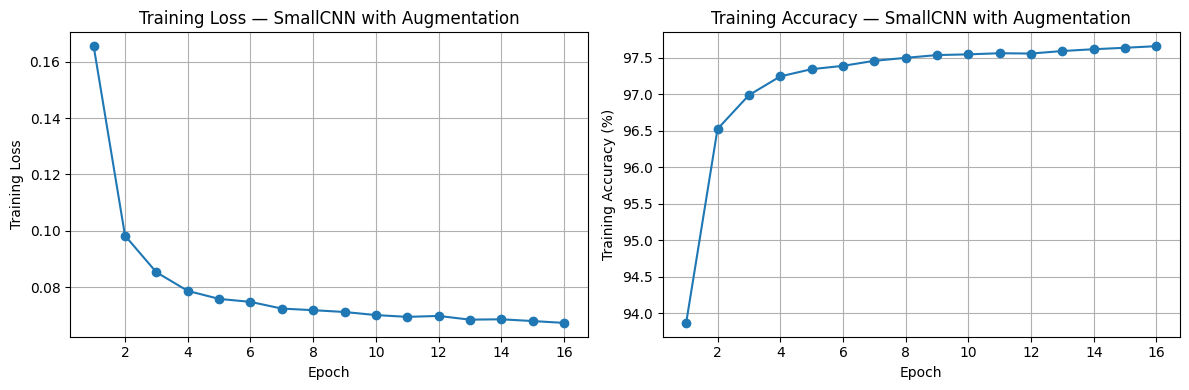

In [29]:
import matplotlib.pyplot as plt

epochs = [record["epoch"] for record in history]
train_losses = [record["train_loss"] for record in history]
train_accuracies = [record["train_accuracy"] * 100 for record in history]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss — SmallCNN with Augmentation")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.title("Training Accuracy — SmallCNN with Augmentation")
plt.grid(True)

plt.tight_layout()
plt.show()

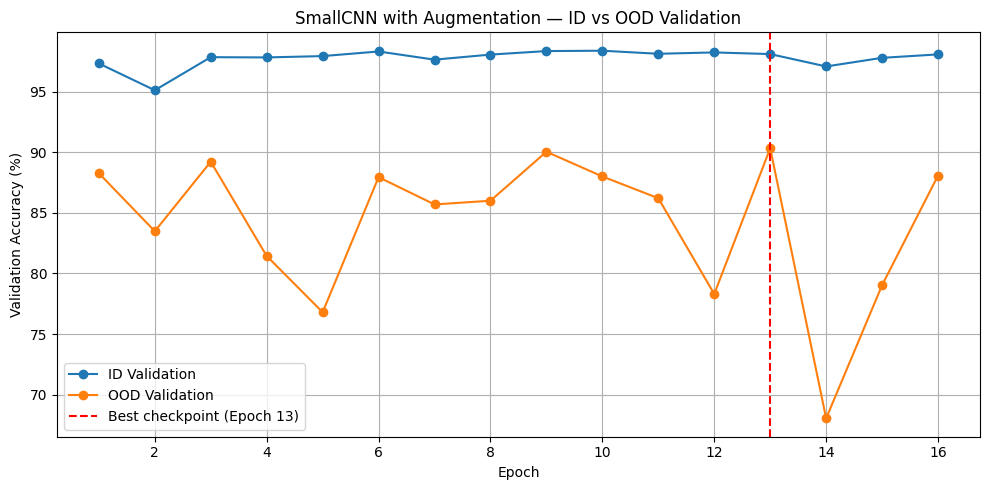

In [30]:
id_accuracy = [
    record["id_metrics"]["accuracy"] * 100
    for record in history
]

ood_accuracy = [
    record["ood_metrics"]["accuracy"] * 100
    for record in history
]

plt.figure(figsize=(10, 5))

plt.plot(epochs, id_accuracy, marker="o", label="ID Validation")
plt.plot(epochs, ood_accuracy, marker="o", label="OOD Validation")

plt.axvline(
    x=13,
    color="red",
    linestyle="--",
    label="Best checkpoint (Epoch 13)"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("SmallCNN with Augmentation — ID vs OOD Validation")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [4]:
import torch
from pathlib import Path

best_checkpoint_path = Path(
    "/mnt/beegfs/home/u283598/final_project/checkpoints/smallcnn_aug_best.pt"
)

best_checkpoint = torch.load(
    best_checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Best checkpoint loaded successfully!")
print("Selected epoch:", best_checkpoint["epoch"])
print(
    "OOD validation accuracy:",
    f"{best_checkpoint['ood_metrics']['accuracy'] * 100:.2f}%"
)

Best checkpoint loaded successfully!
Selected epoch: 13
OOD validation accuracy: 90.33%


In [5]:
model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

print("Model is in evaluation mode:", not model.training)

Model is in evaluation mode: True


In [8]:
from torchvision import transforms

test_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

test_dataset = dataset.get_subset(
    "test",
    transform=test_transform
)

print("Official test dataset loaded!")
print("Number of test images:", len(test_dataset))


Official test dataset loaded!
Number of test images: 85054


In [9]:
from torch.utils.data import DataLoader

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=4,
    pin_memory=torch.cuda.is_available()
)

print("Test DataLoader created successfully!")
print("Number of test images:", len(test_dataset))
print("Number of test batches:", len(test_loader))

Test DataLoader created successfully!
Number of test images: 85054
Number of test batches: 10632


## Official Test Results

The best SmallCNN checkpoint was selected at epoch 13 using
out-of-distribution (OOD) validation balanced accuracy.

The saved model was evaluated on the official Camelyon17-WILDS
test split containing 85,054 image patches. No data augmentation
was applied during testing.

| Metric | Result |
|---|---|
| Test accuracy | 87.65% |
| Test balanced accuracy | 87.65% |
| Test ROC-AUC | 0.9616 |

The SmallCNN with data augmentation achieved 87.65% test accuracy,
compared with the reported 85.39% test accuracy of the SmallCNN
baseline without augmentation.

This is an improvement of 2.26 percentage points, suggesting that
data augmentation helped the model generalize to the held-out
test hospital in this experiment.

In [37]:
import json
from pathlib import Path

results_path = Path(
    "/mnt/beegfs/home/u283598/final_project/smallcnn_aug_test_results.json"
)

with open(results_path, "r") as f:
    test_results = json.load(f)

print("Official Camelyon17 Test Results")
print("Model:", test_results["model"])
print("Best checkpoint epoch:", test_results["checkpoint_epoch"])
print("Test images:", test_results["test_images"])
print(f"Accuracy: {test_results['test_metrics']['accuracy']:.2%}")
print(f"Balanced accuracy: {test_results['test_metrics']['balanced_accuracy']:.2%}")
print(f"ROC-AUC: {test_results['test_metrics']['auc']:.4f}")

Official Camelyon17 Test Results
Model: SmallCNN with data augmentation
Best checkpoint epoch: 13
Test images: 85054
Accuracy: 87.65%
Balanced accuracy: 87.65%
ROC-AUC: 0.9616


## Comparison with Baseline SmallCNN

To provide context for the effect of data augmentation, the following table compares the reported test accuracy of the baseline SmallCNN with the augmented SmallCNN.

| Model | Test Accuracy |
|---|---:|
| SmallCNN without Augmentation (Benjamin) | 85.39% |
| SmallCNN with Augmentation (Ours) | **87.65%** |

**Improvement: +2.26 percentage points**

The augmented SmallCNN achieved higher test accuracy in these experiments. This suggests that data augmentation may improve generalization across hospitals, although additional runs would be needed to confirm the consistency of this improvement.

A detailed comparison of all group models will be presented in a separate comparison notebook.

## Conclusion and Limitations

The SmallCNN with data augmentation achieved **87.65% test accuracy** and **0.9616 ROC-AUC** on the official Camelyon17-WILDS test split. Compared with the reported SmallCNN baseline accuracy of **85.39%**, this represents an improvement of **2.26 percentage points**.
The results suggest that horizontal and vertical flips, 90-degree rotations, and mild color jitter can help improve generalization across hospitals.
